# Tuning and held-out Test/OOD evaluation


Keeps the held-out tuned/untuned evaluation separate from the main benchmark. Test and out-of-distribution families retain their original splits and dataset-level statistical blocks.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")
sources = th.load_aligned_sources()
complete = sources["complete"]


## Family robustness


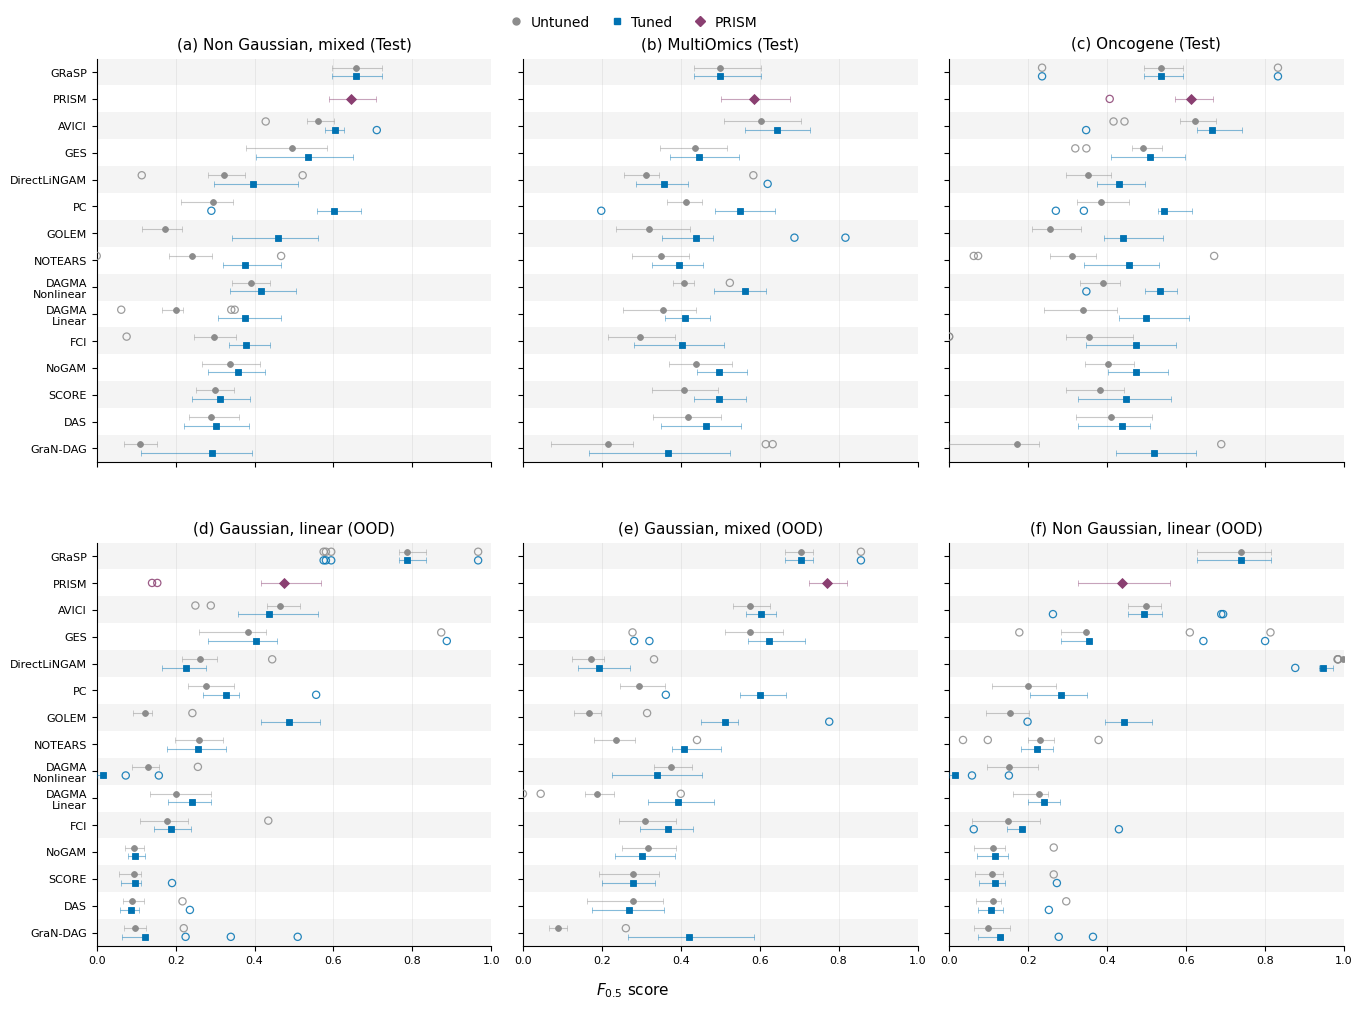

In [2]:
robustness_fits = complete.copy()
robustness = fv.plot_family_robustness(
    robustness_fits,
    metric="fbeta",
    arms=("untuned", "tuned"),
    families=(*th.TEST_FAMILIES, *th.OOD_FAMILIES),
    dataset_seeds=th.DATASET_SEEDS,
    models=fv.DEFAULT_ROBUSTNESS_MODELS,
    include_prism=True,
    model_axis="y",
    uncertainty="iqr",
    show_title=False,
    show_metric_title=False,
)
for result in robustness.values():
    plt.close(result[0])
fig_robustness, _, robustness_panel = fv.plot_family_robustness_panel(
    robustness,
    metric="fbeta",
    families=(*th.TEST_FAMILIES, *th.OOD_FAMILIES),
    family_labels={
        th.TEST_FAMILIES[0]: "Non Gaussian, mixed (Test)",
        th.TEST_FAMILIES[1]: "MultiOmics (Test)",
        th.TEST_FAMILIES[2]: "Oncogene (Test)",
        th.OOD_FAMILIES[0]: "Gaussian, linear (OOD)",
        th.OOD_FAMILIES[1]: "Gaussian, mixed (OOD)",
        th.OOD_FAMILIES[2]: "Non Gaussian, linear (OOD)",
    },
    xlim=(0, 1),
    figsize=(14.5, 10.2),
    font_size=10,
    title_size=11,
    show_fliers=True,
)
robustness_pdf = th.save_pdf(fig_robustness, "prism_robustness_panel.pdf")
display(fig_robustness)
plt.close(fig_robustness)


## Scores, ranks and tuning gains


In [3]:
tuned_table = th.tuned_test_ood(complete)
tuned_display = tuned_table[["Method", "Test F0.5", "OOD F0.5"]]
display(tuned_display)
tuned_ranks = th.ranks_by_family(complete, metric="fbeta")
display(tuned_ranks)
tuned_scope_ranks = th.ranks_by_scope(complete, metric="fbeta")
display(tuned_scope_ranks)
tuning_cells = th.seed_means(complete, "fbeta")
tuning_by_family = (
    tuning_cells.groupby(["dataset", "model", "arm"], observed=True)
    .fbeta.mean()
    .unstack("arm")
    .dropna(subset=["tuned", "untuned"])
)
tuning_by_family["gain"] = tuning_by_family["tuned"] - tuning_by_family["untuned"]


,Method,Test F0.5,OOD F0.5
0,AVICI,0.638 ± 0.053,0.511 ± 0.083
1,PRISM,0.614 ± 0.059,0.561 ± 0.118
2,PC,0.565 ± 0.061,0.404 ± 0.064
3,GRaSP,0.564 ± 0.066,0.743 ± 0.082
4,DAGMA Nonlinear,0.504 ± 0.068,0.123 ± 0.056
5,GES,0.497 ± 0.089,0.460 ± 0.118
6,GOLEM,0.447 ± 0.080,0.481 ± 0.083
7,NoGAM,0.443 ± 0.067,0.172 ± 0.052
8,DAGMA Linear,0.429 ± 0.060,0.291 ± 0.057
9,SCORE,0.419 ± 0.067,0.164 ± 0.055


dataset,Method,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,Median
0,GRaSP,1,3,1,1,1,2,1.0
1,PRISM,1,1,1,2,1,3,1.0
2,GES,1,3,1,2,1,3,1.5
3,AVICI,1,1,1,2,4,3,1.5
4,GOLEM,6,3,1,2,4,3,3.0
5,PC,1,3,1,6,4,7,3.5
6,GraN-DAG,6,3,1,10,7,10,6.5
7,NoGAM,6,3,1,12,7,10,6.5
8,DAGMA Linear,6,3,12,6,7,7,6.5
9,NOTEARS,6,3,12,6,7,7,6.5


scope,Method,OOD,Test,Test + OOD
0,GRaSP,1,1,1
1,AVICI,2,1,1
2,PRISM,2,1,1
3,PC,5,1,4
4,GES,5,5,4
5,GOLEM,2,7,4
6,DAGMA Linear,8,7,7
7,NOTEARS,8,7,7
8,DirectLiNGAM,5,14,7
9,DAGMA Nonlinear,14,5,10
